# Лабораторная работа № 1. Части 1–2

In [14]:
%pip install scipy numpy pandas matplotlib scipy-stubs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 665.2/665.2 kB 2.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [scipy-stubs] [scipy-stubs]

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from scipy.stats import norm, t
from scipy.optimize import brentq
from scipy.integrate import quad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Выбор и фиксация модели

В качестве обычной компоненты возьмём стандартное нормальное распределение.
Для выбросов выберем распределение Стьюдента с тремя степенями свободы и
увеличим его масштаб в 5 раз. Оно симметрично, имеет конечную дисперсию и
тяжёлые хвосты. Долю загрязнения зафиксируем на уровне 10%:
$$X_i=\mu+\sigma U_i,\qquad
U_i\sim0.9N(0,1)+0.1(5T_3),\qquad \sigma>0.$$
Таким образом, $F_{usual}=\Phi$, $F_{outlier}(u)=F_{T_3}(u/5)$,
$\varepsilon=0.1$. Распределения обеих компонент симметричны относительно нуля.
У выбросов распределение Стьюдента с тремя степенями свободы и дополнительным
множителем масштаба 5: его хвосты существенно тяжелее нормальных.

$$F_U(u)=0.9\Phi(u)+0.1F_{T_3}(u/5),\qquad
f_U(u)=0.9\varphi(u)+\frac{0.1}{5}f_{T_3}(u/5).$$

Для численного примера фиксируем $\mu=2$, $\sigma=1.5$, $n=400$ и seed = 42.
Seed фиксируем для воспроизводимости. Истинные значения параметров нужны
для оценки ошибок в численном эксперименте; в формулах оценок положения
и масштаба они не используются.

In [3]:
epsilon = 0.1
outlier_scale = 5
df = 3
mu_true = 2
sigma_true = 1.5
seed = 42

def density(u):
    return (1 - epsilon) * norm.pdf(u) + epsilon * t.pdf(u / outlier_scale, df) / outlier_scale

def distribution(u):
    return (1 - epsilon) * norm.cdf(u) + epsilon * t.cdf(u / outlier_scale, df)

def make_sample(n, rng):
    u = rng.normal(size=n)
    is_outlier = rng.random(n) < epsilon
    u[is_outlier] = outlier_scale * rng.standard_t(df, size=is_outlier.sum())
    return mu_true + sigma_true * u

rng = np.random.default_rng(seed)
x = make_sample(400, rng)
print('Размер выборки:', len(x))
print('Первые 10 наблюдений:', np.round(x[:10], 3))

Размер выборки: 400
Первые 10 наблюдений: [ 2.457  0.44   3.126  3.411 -0.927  2.414  0.098  5.664  1.975  0.72 ]


### Параметр масштаба и стандартное отклонение

В условии $\sigma$ называется масштабом, а свойства оценок формулируются как для
стандартного отклонения. Для выбранной смеси эти величины различаются:
$$E(U)=0,\qquad \operatorname{Var}(T_3)=3,\qquad
\operatorname{Var}(U)=0.9\cdot1+0.1\cdot25\cdot3=8.4,$$
$$\operatorname{SD}(X)=\sigma\sqrt{8.4}.$$
Далее оцениваем параметр модели $\sigma$
Чтобы получить состоятельную оценку стандартного отклонения всей смеси,
любую состоятельную оценку $\sigma$ нужно умножить на $\sqrt{8.4}$.
Эта операция сохраняет свойства сдвига и масштаба.

Var(U) = 8.4
Параметр масштаба sigma = 1.50000
Стандартное отклонение X = 4.34741


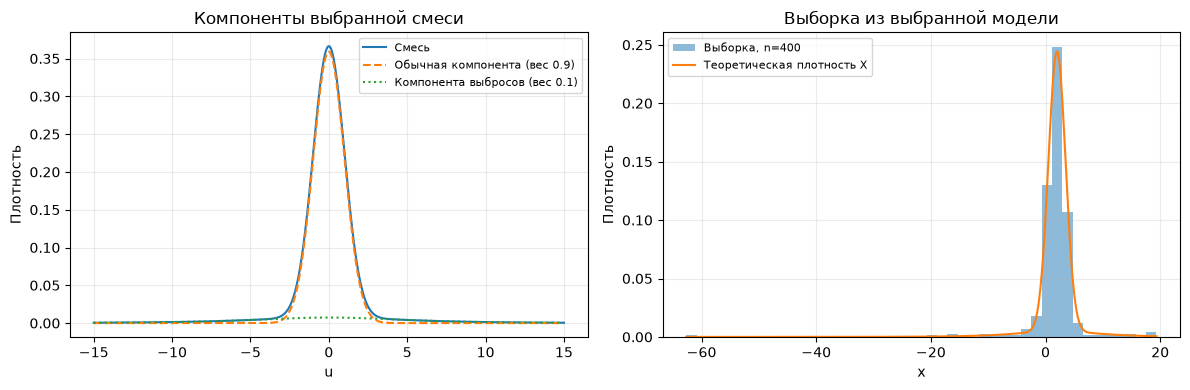

In [4]:
variance_u = (1 - epsilon) + epsilon * outlier_scale**2 * df / (df - 2)
sd_x_true = sigma_true * np.sqrt(variance_u)
print(f'Var(U) = {variance_u:.1f}')
print(f'Параметр масштаба sigma = {sigma_true:.5f}')
print(f'Стандартное отклонение X = {sd_x_true:.5f}')

grid = np.linspace(-15, 15, 1500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(grid, density(grid), label='Смесь')
axes[0].plot(grid, (1 - epsilon) * norm.pdf(grid), '--', label='Обычная компонента (вес 0.9)')
axes[0].plot(grid, epsilon * t.pdf(grid / outlier_scale, df) / outlier_scale,
             ':', label='Компонента выбросов (вес 0.1)')
axes[0].set(xlabel='u', ylabel='Плотность', title='Компоненты выбранной смеси')
axes[0].legend(fontsize=8)
axes[1].hist(x, bins=45, density=True, alpha=0.5, label='Выборка, n=400')
grid_x = np.linspace(x.min(), x.max(), 1500)
axes[1].plot(grid_x, density((grid_x - mu_true) / sigma_true) / sigma_true,
             label='Теоретическая плотность X')
axes[1].set(xlabel='x', ylabel='Плотность', title='Выборка из выбранной модели')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 2. Оценки масштаба

### 2.1. MADN и IQRN

Пусть $\tilde x=\operatorname{Med}(x_1,\ldots,x_n)$,
$\operatorname{MAD}=\operatorname{Med}_i|x_i-\tilde x|$,
$Q_p$ — выборочный квантиль уровня $p$.
Обычные нормированные оценки имеют вид
$$\operatorname{MADN}=\frac{\operatorname{MAD}}{z},\qquad
\operatorname{IQRN}=\frac{Q_{0.75}-Q_{0.25}}{2z},\qquad
z=\Phi^{-1}(0.75)\approx0.67449.$$
Они калиброваны под $N(0,1)$. В нашей смеси квантили иные.
Обозначим через $q>0$ решение $F_U(q)=0.75$.
В силу симметрии $Q_U(0.25)=-q$ и $P(|U|\le q)=1/2$.
Поэтому при $n\to\infty$
$$\operatorname{MAD}\xrightarrow{a.s.}\sigma q,\qquad
Q_{0.75}-Q_{0.25}\xrightarrow{a.s.}2\sigma q,$$
$$\operatorname{MADN},\operatorname{IQRN}
\xrightarrow{a.s.}\sigma\frac qz.$$
Плотность смеси всюду положительна, поэтому медиана и используемые квантили
единственны, и применима состоятельность выборочных квантилей.

Обычные MADN и IQRN **несостоятельны для $\sigma$** при фиксированной выбранной смеси.
Исправляем их заменой нормального делителя на квантиль смеси:
$$\hat\sigma_{\mathrm{MAD}}=\frac{\operatorname{MAD}}q,\qquad
\hat\sigma_{\mathrm{IQR}}=\frac{Q_{0.75}-Q_{0.25}}{2q}.$$
Обе исправленные оценки сильно состоятельны для $\sigma$.
Их предельные значения совпадают, но на конечной выборке сами оценки обычно различны.

In [5]:
q_normal = norm.ppf(0.75)
q = brentq(lambda u: distribution(u) - 0.75, 0, 20)

print(f'Нормальный квантиль z: {q_normal:.8f}')
print(f'Квантиль смеси q:      {q:.8f}')
print(f'Поправка z/q:          {q_normal / q:.8f}')
print(f'Предел MADN/sigma и IQRN/sigma: {q / q_normal:.8f}')
print(f'Предельное завышение: {(q / q_normal - 1) * 100:.2f}%')

Нормальный квантиль z: 0.67448975
Квантиль смеси q:      0.74454384
Поправка z/q:          0.90591006
Предел MADN/sigma и IQRN/sigma: 1.10386234
Предельное завышение: 10.39%


### 2.2. M-оценка масштаба на основе bisquare

Для центра используем медиану $\tilde x$, которая состоятельно оценивает $\mu$.
Используем нормированную bisquare scale функцию:
$$\chi_d(u)=1-\max\{1-u^2/d^2,0\}^3
=\begin{cases}
1-(1-u^2/d^2)^3,&|u|<d,\\
1,&|u|\ge d.
\end{cases}$$
Здесь $\chi_d=\rho_{\mathrm{scale},d}$. Для сравнения рассмотрим $d=2$ и $d=3$:
при меньшем $d$ функция раньше достигает верхней границы, поэтому влияние
больших стандартизованных отклонений ограничивается раньше.
Множитель нормировки функции несущественен, если одинаково изменить правую часть.
Оценка $s>0$ определяется уравнением
$$\frac1n\sum_{i=1}^n\chi_d\!\left(\frac{x_i-\tilde x}{s}\right)=b_d.$$

**Обычная нормальная калибровка:** $b_{N,d}=E_{Z\sim N(0,1)}\chi_d(Z)$.
При нашей смеси её вероятностный предел равен $\sigma r_d$, где
$$E_F\chi_d(U/r_d)=b_{N,d}.$$
Поскольку $r_d\ne1$, такая оценка также несостоятельна для $\sigma$.

**Модификация под смесь:** заменяем правую часть на
$$\boxed{b_{F,d}=E_F\chi_d(U)
=2\int_0^d\chi_d(u)f_U(u)\,du+2[1-F_U(d)]}.$$
Получаем состоятельную оценку $\hat\sigma_{M,d}$ из уравнения с $b_d=b_{F,d}$.
Здесь хвостовое слагаемое необходимо, поскольку вне $[-d,d]$ функция равна 1.

In [15]:
def scale_bisquare(u, d):
    return 1 - np.maximum(1 - (np.asarray(u) / d)**2, 0)**3

def expected_bisquare(r, d, model='mixture'):
    if model == 'mixture':
        pdf, cdf = density, distribution
    elif model == 'normal':
        pdf, cdf = norm.pdf, norm.cdf
    else:
        raise ValueError('Неизвестная модель')
    cutoff = r * d
    integral = 2 * quad(lambda u: scale_bisquare(u / r, d) * pdf(u), 0, cutoff,
                        epsabs=1e-10, epsrel=1e-10)[0]
    return integral + 2 * (1 - cdf(cutoff))

scale_parameters = [2, 3]
b_normal = {d: expected_bisquare(1, d, 'normal') for d in scale_parameters}
b_mixture = {d: expected_bisquare(1, d) for d in scale_parameters}
r_normal = {
    d: brentq(lambda r: expected_bisquare(r, d) - b_normal[d], 0.05, 20)
    for d in scale_parameters
}

calibration_table = pd.DataFrame([
    {'d': d, 'b_normal': b_normal[d], 'b_mixture': b_mixture[d],
     'limit_normal_M / sigma': r_normal[d],
     'limit_corrected_M / sigma': 1.0}
    for d in scale_parameters
])
display(calibration_table.round(6))

,d,b_normal,b_mixture,limit_normal_M / sigma,limit_corrected_M / sigma
0,2,0.397563,0.444521,1.133592,1.0
1,3,0.242654,0.298739,1.201376,1.0


**Почему исправленная M-оценка состоятельна.** Функция
$g_d(r)=E_F\chi_d(U/r)$ непрерывна и строго убывает на $(0,\infty)$:
при увеличении $r$ каждый модуль аргумента уменьшается, а на интервале,
где $0<|U|<dr$, уменьшение строгое и этот интервал имеет положительную вероятность.
Кроме того, $g_d(0+)=1$, $g_d(+\infty)=0$.
Следовательно, уравнение $g_d(r)=b_{F,d}=g_d(1)$ имеет единственное решение $r=1$.
Состоятельность медианы, ограниченность и непрерывность $\chi_d$ и закон больших чисел
дают сходимость выборочного уравнения к этому предельному уравнению.
Используя монотонность и значения по обе стороны от 1, получаем
$\hat\sigma_{M,d}/\sigma\to1$ почти наверное.

Для невырожденных выборок из непрерывной модели положительный корень существует
при достаточно большом $n$ и единственен. При совпадающих наблюдениях
положительного корня может не быть; реализация явно сообщает об этом.
У постоянной выборки масштаб принимаем равным нулю.

In [16]:
def m_scale(sample, d, b):
    sample = np.asarray(sample, dtype=float)
    if sample.ndim != 1 or sample.size < 2 or not np.isfinite(sample).all():
        raise ValueError('Нужна одномерная конечная выборка размера не менее 2')
    if d <= 0 or not 0 < b < 1:
        raise ValueError('Необходимы d > 0 и 0 < b < 1')

    deviations = np.abs(sample - np.median(sample))
    reference = deviations.max()
    if reference == 0:
        return 0.0
    if np.mean(deviations > 0) <= b:
        raise ValueError('Для этой выборки положительного корня нет')

    residuals = deviations / reference
    def equation(log_scale):
        return np.mean(scale_bisquare(residuals / np.exp(log_scale), d)) - b

    lo, hi = -2.0, 2.0
    while equation(lo) <= 0:
        lo -= 2
    while equation(hi) >= 0:
        hi += 2
    root = brentq(equation, lo, hi, xtol=1e-12, rtol=1e-12)
    return reference * np.exp(root)

def estimate_scales(sample):
    sample = np.asarray(sample, dtype=float)
    median = np.median(sample)
    mad = np.median(np.abs(sample - median))
    q25, q75 = np.quantile(sample, [0.25, 0.75], method='linear')
    values = {
        'MADN (normal)': mad / q_normal,
        'IQRN (normal)': (q75 - q25) / (2 * q_normal),
        'MAD / q': mad / q,
        'IQR / (2q)': (q75 - q25) / (2 * q),
    }
    for d in scale_parameters:
        values[f'M bisquare d={d} (normal)'] = m_scale(sample, d, b_normal[d])
        values[f'M bisquare d={d} (mixture)'] = m_scale(sample, d, b_mixture[d])
    return values

sample_estimates = estimate_scales(x)
sample_table = pd.DataFrame([
    {'method': name, 'sigma_hat': value, 'error': value - sigma_true}
    for name, value in sample_estimates.items()
])
display(sample_table.round(6))

,method,sigma_hat,error
0,MADN (normal),1.524852,0.024852
1,IQRN (normal),1.588000,0.088000
2,MAD / q,1.381378,-0.118622
3,IQR / (2q),1.438585,-0.061415
4,M bisquare d=2 (normal),1.583044,0.083044
5,M bisquare d=2 (mixture),1.394854,-0.105146
6,M bisquare d=3 (normal),1.685890,0.185890
7,M bisquare d=3 (mixture),1.400630,-0.099370


### 2.3. Свойства сдвига и масштаба

Для оценки масштаба $T$ требуются
$$T(x_1+a,\ldots,x_n+a)=T(x_1,\ldots,x_n),$$
$$T(bx_1,\ldots,bx_n)=|b|T(x_1,\ldots,x_n),$$
или совместно $T(a+bx)=|b|T(x)$.

1. **MADN и исправленная MAD.** При $y_i=a+bx_i$ медиана преобразуется как
   $\tilde y=a+b\tilde x$, поэтому $|y_i-\tilde y|=|b||x_i-\tilde x|$.
   Медиана модулей отклонений умножается на $|b|$; делители $z$ и $q$ постоянны.
2. **IQRN и исправленная IQR.** При $b>0$ квантили преобразуются как
   $Q_p(y)=a+bQ_p(x)$. При $b<0$ порядок меняется:
   $Q_p(y)=a+bQ_{1-p}(x)$. Поэтому межквартильный размах умножается на $|b|$.
   Используемая линейная интерполяция квантилей сохраняет эти равенства.
3. **Bisquare M-оценки с любой из двух калибровок.** Если $s$ решает уравнение
   для $x$, то при $b\ne0$ значение $|b|s$ решает его для $y$:
   $$\chi_d\!\left(\frac{y_i-\tilde y}{|b|s}\right)
   =\chi_d\!\left(\operatorname{sgn}(b)\frac{x_i-\tilde x}{s}\right)
   =\chi_d\!\left(\frac{x_i-\tilde x}{s}\right).$$
   Использованы чётность $\chi_d$ и единственность положительного корня.
   При $b=0$ выборка постоянна и принятый масштаб равен 0.

Таким образом, все рассмотренные оценки обладают нужными свойствами
на области своего определения. Эти свойства сами по себе не обеспечивают состоятельность.
Проверим равенства на данных, включая отрицательный множитель.

In [17]:
equivariance_rows = []
base = estimate_scales(x)
for a, multiplier in [(7, 1), (0, 2.5), (-3, 0.4), (11, -3), (2, 0)]:
    transformed = estimate_scales(a + multiplier * x)
    for name, original in base.items():
        expected = abs(multiplier) * original
        actual = transformed[name]
        equivariance_rows.append([name, a, multiplier, actual, expected, abs(actual - expected)])
        assert np.isclose(actual, expected, atol=1e-10, rtol=1e-10)

equivariance = pd.DataFrame(equivariance_rows,
                           columns=['method', 'a', 'b', 'actual', 'expected', 'abs_error'])
display(equivariance.groupby('method', sort=False)['abs_error'].max().to_frame())
print('Проверены сдвиг, изменение масштаба, отрицательный множитель и постоянная выборка.')

,abs_error
method,
MADN (normal),1.998401e-15
IQRN (normal),6.661338e-16
MAD / q,1.776357e-15
IQR / (2q),4.440892e-16
M bisquare d=2 (normal),4.440892e-16
M bisquare d=2 (mixture),4.440892e-16
M bisquare d=3 (normal),0.000000e+00
M bisquare d=3 (mixture),1.332268e-15


Проверены сдвиг, изменение масштаба, отрицательный множитель и постоянная выборка.


### 2.4. Эмпирическая проверка состоятельности

Чтобы проследить изменение точности при росте объёма данных, используем
по $R=400$ выборок при $n=100,400,1000$.
Для этого эксперимента создадим отдельный генератор с seed = 43.
Все оценки получают одни и те же выборки, чтобы сравнение методов было сопоставимым.
В каждом повторении медиана и все оценки масштаба вычисляются заново.

Для оценки $\hat\sigma$ сравним среднее, смещение, стандартное отклонение и RMSE:
$$\operatorname{Bias}=\overline{\hat\sigma}-\sigma,\qquad
\operatorname{RMSE}=\sqrt{\frac1{R_*}\sum_{r=1}^{R_*}
(\hat\sigma^{(r)}-\sigma)^2}.$$
Дополнительно показываем среднее $\hat\sigma/\sigma$, его теоретический предел
и Monte Carlo ошибку среднего $\operatorname{SD}(\hat\sigma)/(\sigma\sqrt{R_*})$.
Она характеризует точность моделирования среднего, а не разброс отдельной оценки.
Число неудачных повторений сохраняется в `failures`; метрики рассчитаны по успешным.
Конечное моделирование иллюстрирует доказанные предельные свойства.

In [18]:
repeats = 400
sample_sizes = [100, 400, 1000]
rng_mc = np.random.default_rng(seed + 1)
samples_by_n = {
    n: [make_sample(n, rng_mc) for repetition in range(repeats)]
    for n in sample_sizes
}
names = list(sample_estimates)
estimates_by_n = {}

for n in sample_sizes:
    values = np.full((repeats, len(names)), np.nan)
    for repetition, sample in enumerate(samples_by_n[n]):
        # Отдельная обработка каждой M-оценки сохраняет остальные результаты при сбое.
        median = np.median(sample)
        mad = np.median(np.abs(sample - median))
        q25, q75 = np.quantile(sample, [0.25, 0.75], method='linear')
        row = {'MADN (normal)': mad / q_normal,
               'IQRN (normal)': (q75 - q25) / (2 * q_normal),
               'MAD / q': mad / q, 'IQR / (2q)': (q75 - q25) / (2 * q)}
        for d in scale_parameters:
            for calibration, constants in [('normal', b_normal), ('mixture', b_mixture)]:
                try:
                    row[f'M bisquare d={d} ({calibration})'] = m_scale(sample, d, constants[d])
                except (RuntimeError, ValueError):
                    row[f'M bisquare d={d} ({calibration})'] = np.nan
        values[repetition] = [row[name] for name in names]
    estimates_by_n[n] = values
    print(f'Готово: n={n}, повторений={repeats}')

Готово: n=100, повторений=400
Готово: n=400, повторений=400
Готово: n=1000, повторений=400


In [19]:
limits = {'MADN (normal)': q / q_normal, 'IQRN (normal)': q / q_normal,
          'MAD / q': 1.0, 'IQR / (2q)': 1.0}
for d in scale_parameters:
    limits[f'M bisquare d={d} (normal)'] = r_normal[d]
    limits[f'M bisquare d={d} (mixture)'] = 1.0

simulation_rows = []
for n in sample_sizes:
    for j, name in enumerate(names):
        values = estimates_by_n[n][:, j]
        values = values[np.isfinite(values)]
        count = len(values)
        mean = values.mean() if count else np.nan
        sd = values.std(ddof=1) if count > 1 else np.nan
        rmse = np.sqrt(np.mean((values - sigma_true)**2)) if count else np.nan
        simulation_rows.append([n, name, mean - sigma_true, sd, rmse, mean / sigma_true,
                                limits[name], sd / (sigma_true * np.sqrt(count)) if count else np.nan,
                                repeats - count])

simulation = pd.DataFrame(simulation_rows,
    columns=['n', 'method', 'bias_sigma', 'SD_sigma', 'RMSE_sigma',
             'mean / sigma', 'limit / sigma', 'MCSE_ratio', 'failures'])
display(simulation.round(6))

,n,method,bias_sigma,SD_sigma,RMSE_sigma,mean / sigma,limit / sigma,MCSE_ratio,failures
0,100,MADN (normal),0.134007,0.201622,0.241883,1.089338,1.103862,0.006721,0
1,100,IQRN (normal),0.125643,0.198156,0.234422,1.083762,1.103862,0.006605,0
2,100,MAD / q,-0.019737,0.182651,0.183487,0.986842,1.000000,0.006088,0
3,100,IQR / (2q),-0.027313,0.179512,0.181356,0.981791,1.000000,0.005984,0
4,100,M bisquare d=2 (normal),0.184902,0.162352,0.245929,1.123268,1.133592,0.005412,0
5,100,M bisquare d=2 (mixture),-0.015338,0.145442,0.146068,0.989775,1.000000,0.004848,0
6,100,M bisquare d=3 (normal),0.293802,0.187168,0.348230,1.195868,1.201376,0.006239,0
7,100,M bisquare d=3 (mixture),-0.009737,0.146369,0.146509,0.993509,1.000000,0.004879,0
8,400,MADN (normal),0.161342,0.101048,0.190306,1.107561,1.103862,0.003368,0
9,400,IQRN (normal),0.156012,0.100166,0.185332,1.104008,1.103862,0.003339,0


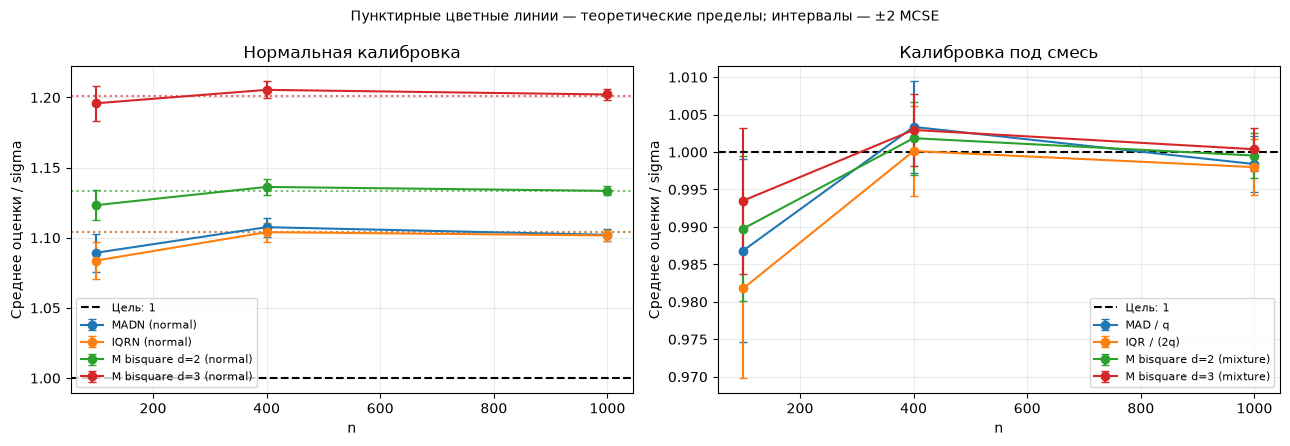

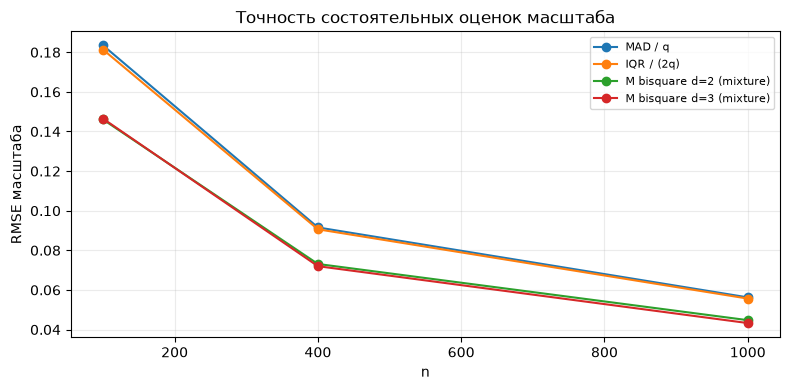

In [20]:
normal_names = ['MADN (normal)', 'IQRN (normal)'] + [f'M bisquare d={d} (normal)' for d in scale_parameters]
corrected_names = ['MAD / q', 'IQR / (2q)'] + [f'M bisquare d={d} (mixture)' for d in scale_parameters]
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, selected, title in zip(axes, [normal_names, corrected_names],
                               ['Нормальная калибровка', 'Калибровка под смесь']):
    for name, color in zip(selected, colors):
        rows = simulation[simulation['method'] == name]
        ax.errorbar(rows['n'], rows['mean / sigma'], yerr=2 * rows['MCSE_ratio'],
                    fmt='o-', capsize=3, color=color, label=name)
        if name in normal_names:
            ax.axhline(limits[name], color=color, linestyle=':', alpha=0.7)
    ax.axhline(1, color='black', linestyle='--', label='Цель: 1')
    ax.set(xlabel='n', ylabel='Среднее оценки / sigma', title=title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.suptitle('Пунктирные цветные линии — теоретические пределы; интервалы — ±2 MCSE', fontsize=10)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
for name, color in zip(corrected_names, colors):
    rows = simulation[simulation['method'] == name]
    plt.plot(rows['n'], rows['RMSE_sigma'], 'o-', color=color, label=name)
plt.xlabel('n')
plt.ylabel('RMSE масштаба')
plt.title('Точность состоятельных оценок масштаба')
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [21]:
largest_n = simulation[simulation['n'] == max(sample_sizes)]
print(f'При n={max(sample_sizes)}:')
display(largest_n[['method', 'bias_sigma', 'RMSE_sigma', 'mean / sigma',
                   'limit / sigma', 'failures']].round(6))
print('Всего неудачных оценок:', int(simulation['failures'].sum()))

При n=1000:


,method,bias_sigma,RMSE_sigma,mean / sigma,limit / sigma,failures
16,MADN (normal),0.153130,0.165220,1.102086,1.103862,0
17,IQRN (normal),0.152457,0.164334,1.101638,1.103862,0
18,MAD / q,-0.002413,0.056255,0.998391,1.000000,0
19,IQR / (2q),-0.003023,0.055650,0.997985,1.000000,0
20,M bisquare d=2 (normal),0.200146,0.206102,1.133431,1.133592,0
21,M bisquare d=2 (mixture),-0.000711,0.044751,0.999526,1.000000,0
22,M bisquare d=3 (normal),0.303167,0.308086,1.202112,1.201376,0
23,M bisquare d=3 (mixture),0.000558,0.043291,1.000372,1.000000,0


Всего неудачных оценок: 0


**Результаты моделирования.** При $n=1000$ средние отношения оценки к $\sigma$
для обычных MADN и IQRN равны 1.10209 и 1.10164, близко к пределу 1.10386.
У нормально калиброванных M-оценок отношения равны 1.13343 при $d=2$ и
1.20211 при $d=3$; их пределы — 1.13359 и 1.20138. Значит, рост объёма
выборки не устраняет ошибку калибровки.

У исправленных оценок при $n=1000$ модули смещения не превышают 0.00303.
RMSE модифицированной MADN уменьшается с 0.18349 при $n=100$ до 0.05625
при $n=1000$. При $n=1000$ RMSE исправленной IQR равна 0.05565,
а у bisquare с $d=2$ и $d=3$ — 0.04475 и 0.04329.
В этом эксперименте M-оценки точнее, но требуют численного решения уравнения.
Все 9600 оценок (8 методов × 400 повторений × 3 объёма) вычислены успешно.

### 2.5. Выбор оценки масштаба

Для дальнейшей работы выбираем **модифицированную MADN**:
$$\boxed{\hat\sigma=\frac{\operatorname{Med}_i|x_i-\operatorname{Med}(x)|}{q}},
\qquad F_U(q)=0.75.$$
Её состоятельность и свойства сдвига и масштаба установлены выше.
Оценка выражается через медианы, слабо реагирует на величину отдельных
больших наблюдений и после однократного вычисления $q$ не требует
численного решения уравнения для каждой выборки. Дополнительный параметр
настройки $d$ также не нужен.

В проведённом эксперименте исправленные M-оценки имеют меньшую RMSE.
Поэтому выбор MADN — компромисс в пользу простоты вычисления при сохранении
состоятельности и устойчивости, а не утверждение о наилучшей точности.
Её RMSE уменьшается с ростом $n$, а смещение при $n=1000$ мало по сравнению
со стандартным отклонением оценки.

Если начинать с обычной MADN, поправка записывается как
$$\hat\sigma=\operatorname{MADN}\frac{\Phi^{-1}(0.75)}q.$$
Эту формулу используем в итоговом расчёте.

In [23]:
median_x = np.median(x)
mad = np.median(np.abs(x - median_x))
madn = mad / q_normal
sigma_madn = madn * q_normal / q

print(f'q для смеси: {q:.5f}')
print(f'Обычная MADN: {madn:.5f}')
print(f'Модифицированная MADN: {sigma_madn:.5f}')
print(f'Предельное завышение обычной MADN: {(q / q_normal - 1) * 100:.2f}%')
print(f'Оценка SD(X), если требуется именно стандартное отклонение: {sigma_madn * np.sqrt(variance_u):.5f}')

selected = simulation[simulation['method'] == 'MAD / q']
print('Эмпирическая точность выбранной оценки:')
display(selected[['n', 'bias_sigma', 'SD_sigma', 'RMSE_sigma', 'failures']].round(6))

q для смеси: 0.74454
Обычная MADN: 1.52485
Модифицированная MADN: 1.38138
Предельное завышение обычной MADN: 10.39%
Оценка SD(X), если требуется именно стандартное отклонение: 4.00362
Эмпирическая точность выбранной оценки:


,n,bias_sigma,SD_sigma,RMSE_sigma,failures
2,100,-0.019737,0.182651,0.183487,0
10,400,0.005026,0.091541,0.091564,0
18,1000,-0.002413,0.056274,0.056255,0
